BrM Nanostring Cosmx 6k (36 Samples, 3M cells)
=======================

In [ ]:
# ==============================================================================
# CosMx Brain Metastasis Spatial Transcriptomics
# ==============================================================================
# %pwd

# 加载相关工具包
from pathlib import Path
import pandas as pd
pd.set_option("display.max_columns", None)

import numpy as np
import os
import matplotlib.pyplot as plt
import palantir
import warnings
import gc
import pickle
import random
import torch

import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity


import anndata as ad

from scipy.stats import gaussian_kde, entropy
from scipy.sparse import csr_matrix
import seaborn as sns

import sklearn
print(sklearn.__version__)  # 应输出 1.3.2

import scanpy as sc
import pyucell as uc

# pip install squidpy==1.3.1 scanpy==1.9.3 anndata==0.9.0 numpy==1.23.5 scipy==1.9.3 pandas==1.5.3 scikit-image==0.19.3 tifffile==2022.10.10 pillow==9.4.0 matplotlib==3.6.3 seaborn==0.12.2 numba==0.56.4 networkx==2.8.8 scikit-learn==1.2.2 statsmodels==0.13.5 omnipath==1.0.7   # 旧版 squidpy 才可以读入 
import squidpy as sq
print(sq.__version__)

import celltypist

# from napari_spatialdata import Interactive
import spatialdata as sd
import spatialdata_io

from scipy.spatial import distance_matrix
from collections import defaultdict

from statannotations.Annotator import Annotator
from itertools import combinations  # 自动生成所有两两配对

warnings.filterwarnings('ignore')
sc.logging.print_header()


1.9.0
1.8.1


/home/dingrong/miniconda3/envs/R453/lib/python3.14/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


Package,Version
pandas,2.3.3
numpy,2.4.3
matplotlib,3.10.9
palantir,1.4.4
torch,2.11.0 (2.10.0)
networkx,3.6.1
scikit-learn,1.9.0
anndata,0.12.16
scipy,1.17.1
seaborn,0.13.2


In [2]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


In [3]:
ad.settings.allow_write_nullable_strings = True  # 开启允许保存字符串类型

fig_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result"
# fig_dir = Path().resolve() / "BM_Cosmx_Py"/"Result"
os.makedirs(fig_dir, exist_ok=True)

# ===================== PLOT SETTINGS =====================
sc.set_figure_params(
	facecolor="white", figsize=(6,6), dpi=300, fontsize=11, frameon=True
)
sc.settings.verbosity = 3
sc.settings.n_jobs = 16
sc.settings.figdir = fig_dir

plt.rcParams["savefig.dpi"] = 300
# plt.rcParams["save.bbox_inches"] = "tight"
plt.rcParams['axes.unicode_minus'] = False


# ===================== UTILITY FUNCTIONS =====================
def save_fig(name, fig_dir):
	plt.savefig(os.path.join(fig_dir, f"{name}.png"), dpi=300, bbox_inches="tight" )
	plt.savefig(os.path.join(fig_dir, f"{name}.pdf"), dpi=300, bbox_inches="tight" )
	# plt.close()

# 自动缩放空间坐标
def auto_scale_spatial(adata, target_scale=1000):
	"""
	自动将空间坐标缩放到 [0, target_scale] 范围
	"""
	x = adata.obsm["spatial"][:, 0]
	y = adata.obsm["spatial"][:, 1]
	# 缩放到 0~1
	x = (x - x.min()) / (x.max() - x.min())
	y = (y - y.min()) / (y.max() - y.min())
	# 放大到目标范围
	x = x * target_scale
	y = y * target_scale
	# 放回
	adata.obsm["spatial"] = np.column_stack([x, y])

def plot_umap_spatial(adata, color_key, fig_dir, suffix=""):
	sc.pl.umap(adata, color=color_key, show=False)   # , save=f"umap_{color_key}{suffix}"
	save_fig(f"umap.{color_key}{suffix}", fig_dir)
	for sid in sample_list:
		sub = adata[adata.obs["sample"] == sid].copy()
		if sub.n_obs < 50:
			continue
		# 修复空间坐标
		# sub.obsm["spatial"] = sub.obs[["CenterX_global_px", "CenterY_global_px"]].values  # 直接提取坐标画出来图是反的，CosMx 仪器：Y 轴向下增大（图像坐标系，左上角为原点）， Matplotlib/squidpy：Y 轴向上增大（数学坐标系，左下角为原点）
		# ✅ 永久翻转 Y 坐标
		x = sub.obs["CenterX_global_px"].values
		y = sub.obs["CenterY_global_px"].values
		y_flipped = y.max() + y.min() - y
		sub.obsm["spatial"] = np.column_stack([x, y_flipped])
		# 即使有 obsm["spatial"]，squidpy 依然会强制检查 adata.uns["spatial"], 强制添加 squidpy 必须要的空结构，解决 KeyError
		sub.uns["spatial"] = {"images": {}}
		# # 自动缩放你的 sub 数据坐标
		# auto_scale_spatial(sub, target_scale=1000)
		# sq.pl.spatial_scatter(sub, color=color_key, size=1, img=False, frameon=False, shape=None)  # , library_key="fov" , palette="tab20" , save=f"spatial.{color_key}.{sid}.{suffix}" # img=False, NanoString CosMx 数据，没有组织病理学图像（H&E）
		sq.pl.spatial_scatter(sub, color=color_key, size=1, img=False, frameon=False, legend_fontsize=4, shape=None)  # , library_key="fov" , save=f"spatial.{color_key}.{sid}.{suffix}"  , squidpy 中 legend_loc 只能填：right / left / top / bottom / center ,  scanpy 支持 legend_loc='outside right'
		# ax.invert_yaxis()  # ✅ 临时翻转 Y 轴，匹配 CosMx 原始图像
		save_fig(f"spatial_{color_key}.{sid}{suffix}", fig_dir)

def plot_enrich_bar(df, x_col, y_col, title, name, fig_dir, topn=15):
	plt.figure(figsize=(10,6))
	df_top = df.head(topn).sort_values(x_col, ascending=True)
	sns.barplot(data=df_top, x=x_col, y=y_col)
	plt.title(title, fontsize=12)
	plt.tight_layout()
	save_fig(name, fig_dir)

def plot_boxplot(df, cols, name, fig_dir, title=""):
	plt.figure(figsize=(10,6))
	ax = df[cols].boxplot(grid=False)
	ax.grid(False)  # 去掉网格线
	plt.title(title)
	plt.tight_layout()
	save_fig(name, fig_dir)

样本信息
---------------------------------------------

In [ ]:
# ===================== GLOBAL CONFIG =====================
project_name = "BM_Cosmx_Py"
out_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result/"
# out_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result.bk/"
fig_dir = os.path.join(out_dir, "figures")
csv_dir = os.path.join(out_dir, "tables")
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)

In [ ]:

adata = sc.read_h5ad(os.path.join(out_dir, f"{project_name}.h5ad"))
adata


【Step 10.1】 Cell/Sample Composition Statistics
---------------------------------------------

In [14]:

# ==============================================================================
# METHODS: 10. Cell/Sample Composition Statistics
# Detailed Description: 
# ==============================================================================
print("\n【Step 10.1】 CellType")
fig_dir = os.path.join(out_dir, "Step10_Composition", "Composition_Statistics")
csv_dir = os.path.join(out_dir, "Step10_Composition", "Composition_Statistics")
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)



【Step 10.1】 CellType


In [15]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


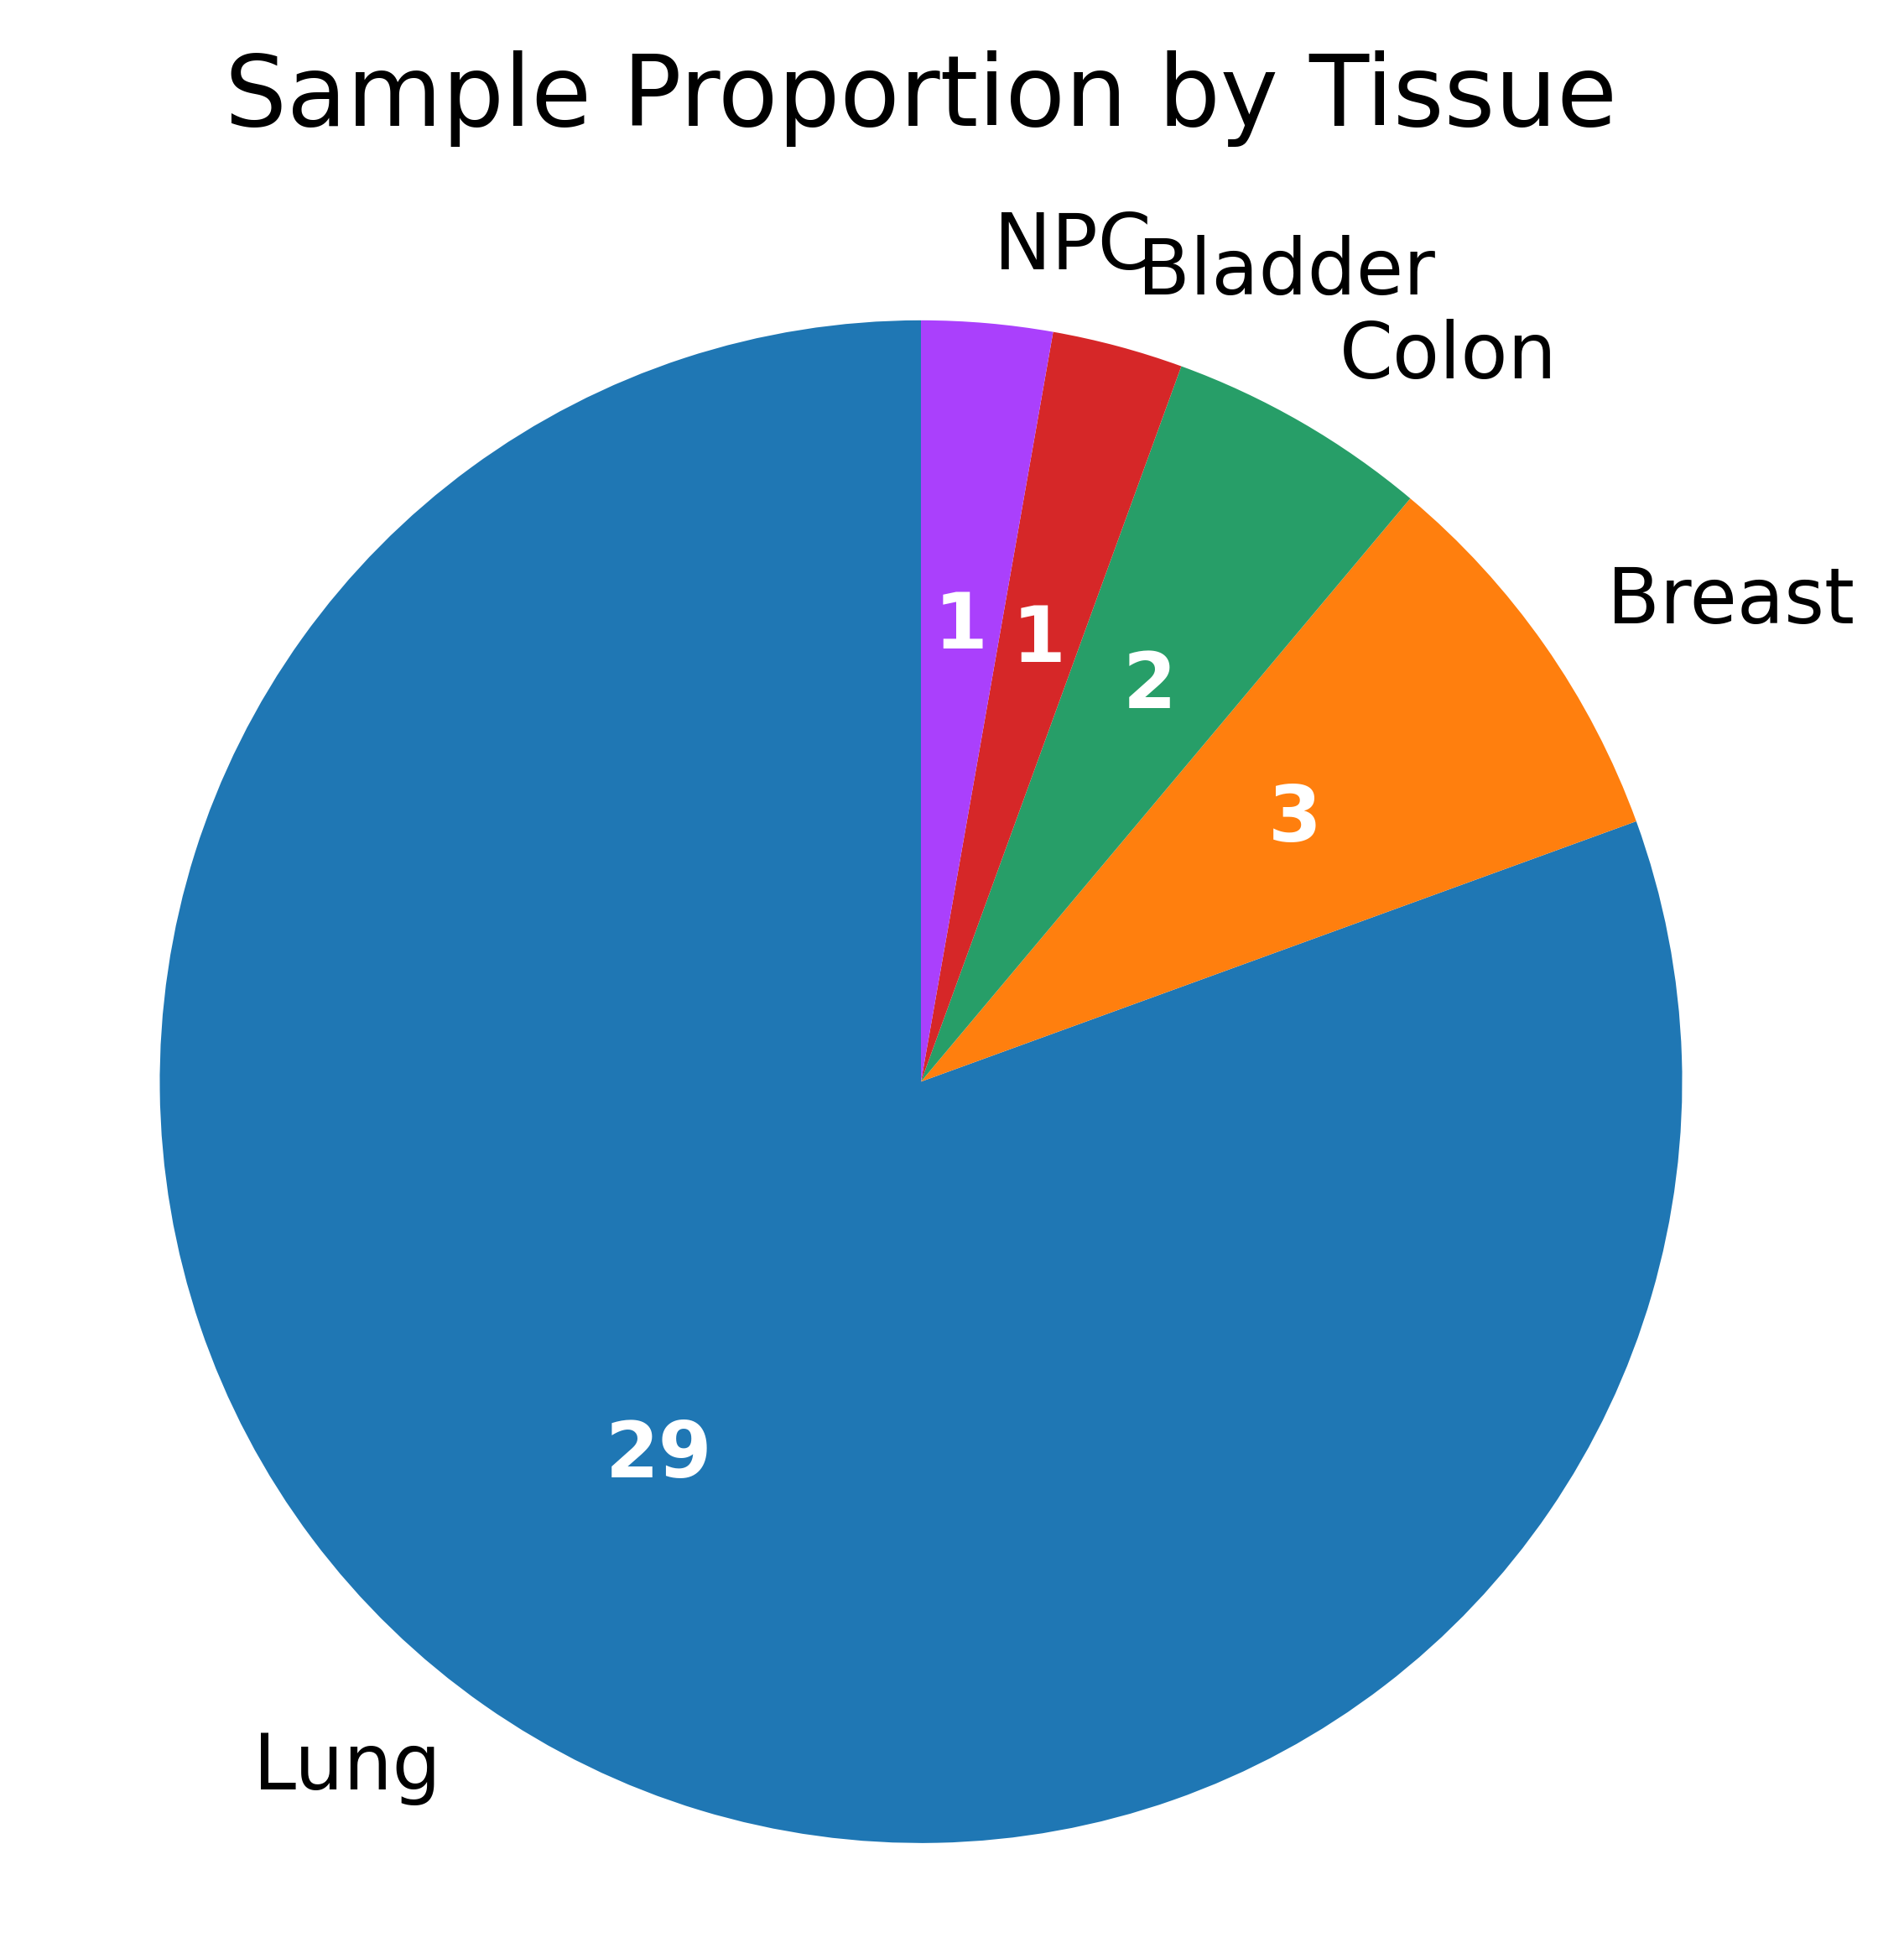

In [16]:
# 提取每个样本唯一对应的Tissue
df_meta = adata.obs[["sample", "Tissue"]].drop_duplicates(subset="sample")
tissue_count = df_meta["Tissue"].value_counts()

# 绘图
plt.figure(figsize=(4, 4))
wedges, texts, autotexts = plt.pie(
	tissue_count.values,
	labels=tissue_count.index,
	autopct=lambda pct: f"{int(pct/100 * sum(tissue_count.values))}",
	# autopct=lambda pct: f"{pct:.1f}%\n(n={int(pct/100 * sum(tissue_count.values))})",
	startangle=90,
	textprops={"fontsize": 11}
)
# 美化文字
for autotext in autotexts:
	autotext.set_color("white")
	autotext.set_fontweight("bold")
plt.title("Sample Proportion by Tissue", fontsize=14, pad=20)
plt.axis("equal")
plt.tight_layout()
save_fig("Sample_Tissue_PieChart", fig_dir)

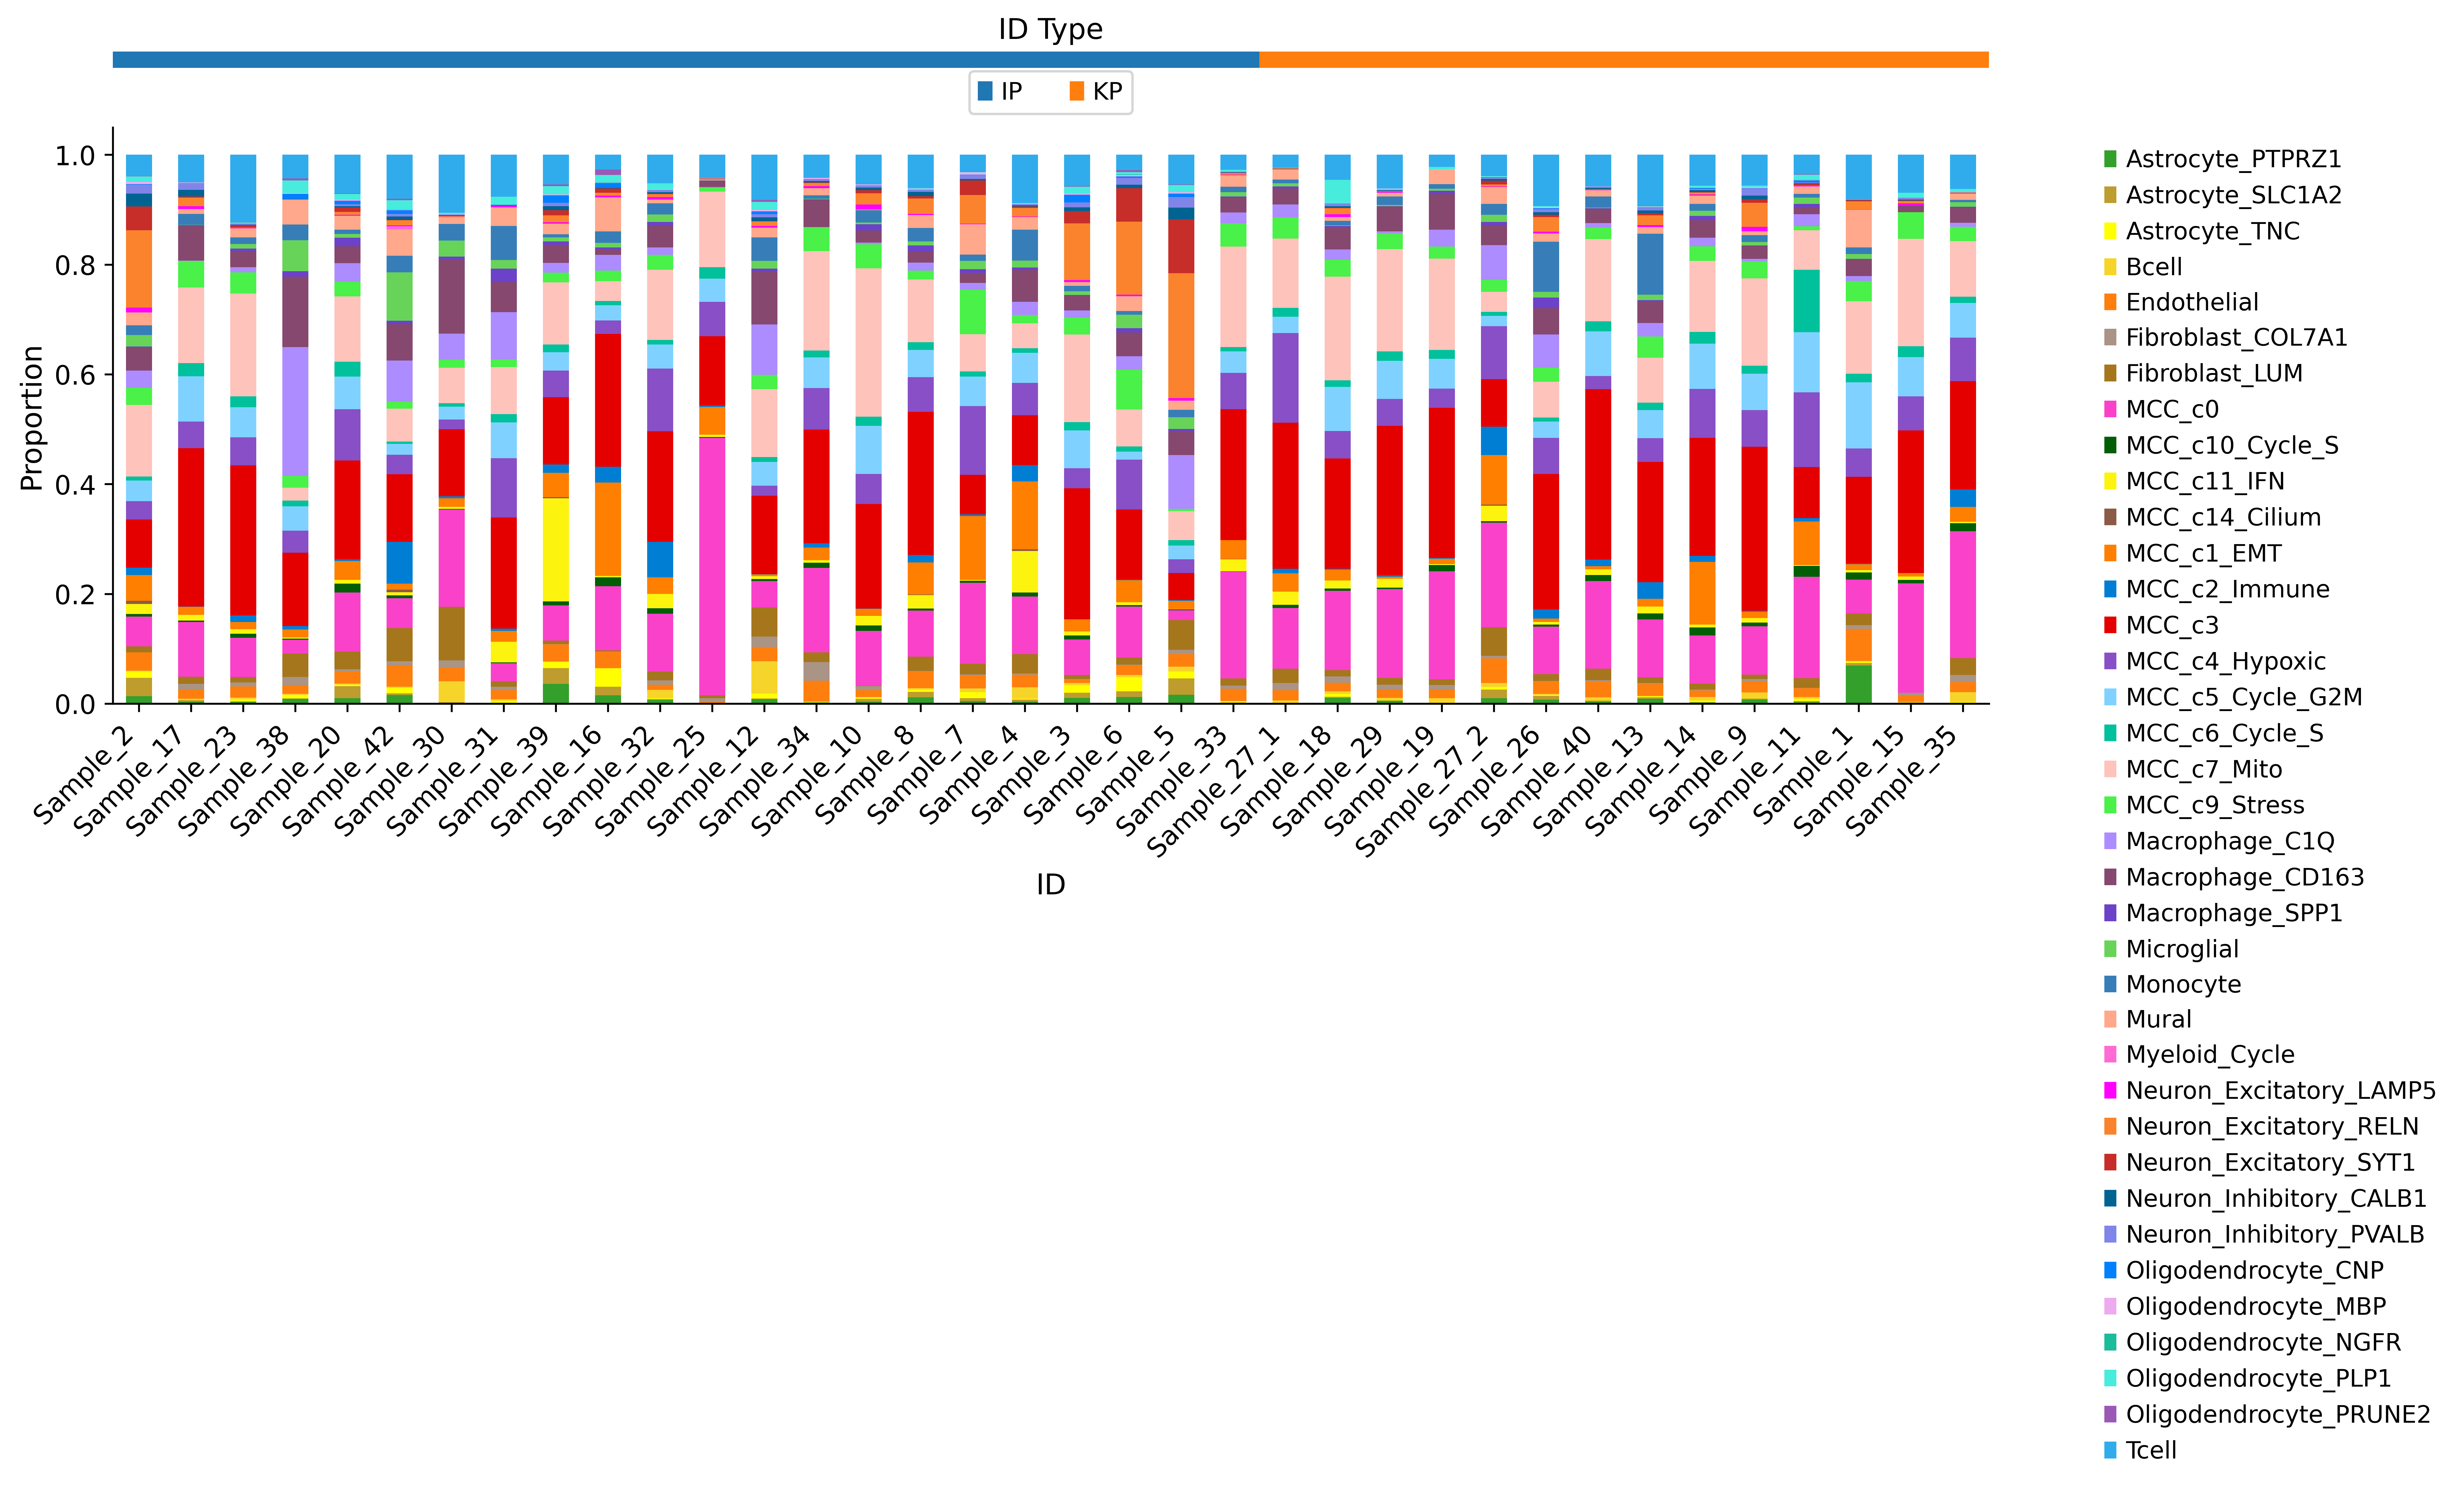

: 

In [ ]:
# 【公共部分：样本按 Type 排序】
df_obs = adata.obs.copy()
ID_type = df_obs[["ID", "Type"]].drop_duplicates().set_index("ID")
ID_order = ID_type.sort_values("Type").index.tolist()
type_labels_sorted = ID_type.loc[ID_order]["Type"].values
unique_types = np.unique(type_labels_sorted)
# Type 配色
type_palette = sns.color_palette("tab10", len(unique_types))
type_color_map = dict(zip(unique_types, type_palette))

# ==============================
# 6. 每个 ID 的 CellType 比例（堆叠柱状图 + 顶部Type颜色条）
# ==============================
fig, (ax_top, ax_main) = plt.subplots(2, 1, figsize=(14, 5), gridspec_kw={'height_ratios': [0.3, 10]})
# 比例数据 + 排序
ct_ID = pd.crosstab(df_obs['ID'], df_obs['CellType']).loc[ID_order]
ct_ID_prop = ct_ID.div(ct_ID.sum(axis=1), axis=0)
# 顶部 Type 颜色条
for i, t in enumerate(type_labels_sorted):
    ax_top.bar(i, 1, color=type_color_map[t], width=1)
ax_top.set_xlim(-0.5, len(ID_order)-0.5)
ax_top.axis("off")
ax_top.set_title("ID Type", fontsize=12, pad=5)
# Type 图例
handles_type = [plt.Rectangle((0,0),1,1, color=type_color_map[t]) for t in unique_types]
ax_top.legend(handles_type, unique_types, loc="upper center", bbox_to_anchor=(0.5, 0.5), ncol=6)
# 主图：堆叠柱状图
cell_types = df_obs["CellType"].cat.categories
color_map = dict(zip(cell_types, adata.uns["CellType_colors"]))
colors = [color_map[ct] for ct in ct_ID_prop.columns]
ct_ID_prop.plot(kind='bar', stacked=True, color=colors, ax=ax_main)
ax_main.grid(False)
ax_main.legend(bbox_to_anchor=(1.05, 1), loc="upper left", frameon=False, fontsize=10)
# ax_main.set_title('CellType per ID', fontsize=14, pad=15)
ax_main.set_ylabel('Proportion', fontsize=12)
ax_main.set_xlabel('ID', fontsize=12)
ax_main.set_xticklabels(ax_main.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
save_fig('ID_CellType_proportion_stack', fig_dir)


In [ ]:

div_df = []
for sid in sample_list:
	sub = adata[adata.obs["sample"]==sid]
	type = sub.obs["Type"].unique()[0]
	tissue = sub.obs["Tissue"].unique()[0]
	location = sub.obs["Location"].unique()[0]
	ct_counts = sub.obs["CellType"].value_counts()
	shannon = -sum( (ct_counts/ct_counts.sum()) * np.log(ct_counts/ct_counts.sum()) )
	simpson = 1 - sum( (ct_counts**2) / (ct_counts.sum()**2) )
	div_df.append([sid, type, tissue, location, sub.n_obs, shannon, simpson])
div_df = pd.DataFrame(div_df, columns=["sample", "Type", "Tissue", "Location", "cell_count", "shannon_diversity", "simpson_index"])
div_df.to_csv(os.path.join(csv_dir, "sample_heterogeneity_index.csv"), index=False)
div_df.head()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

IP vs. KP: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.033e-02 U_stat=2.260e+02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

IP vs. KP: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:4.597e-02 U_stat=2.160e+02
✅ Sample heterogeneity quantification completed
   ├─ Mean Shannon diversity: 2.626
   ├─ Mean Simpson index: 0.888
   ├─ Most diverse sample: X15S8793_2
   └─ Least diverse sample: X23s30119


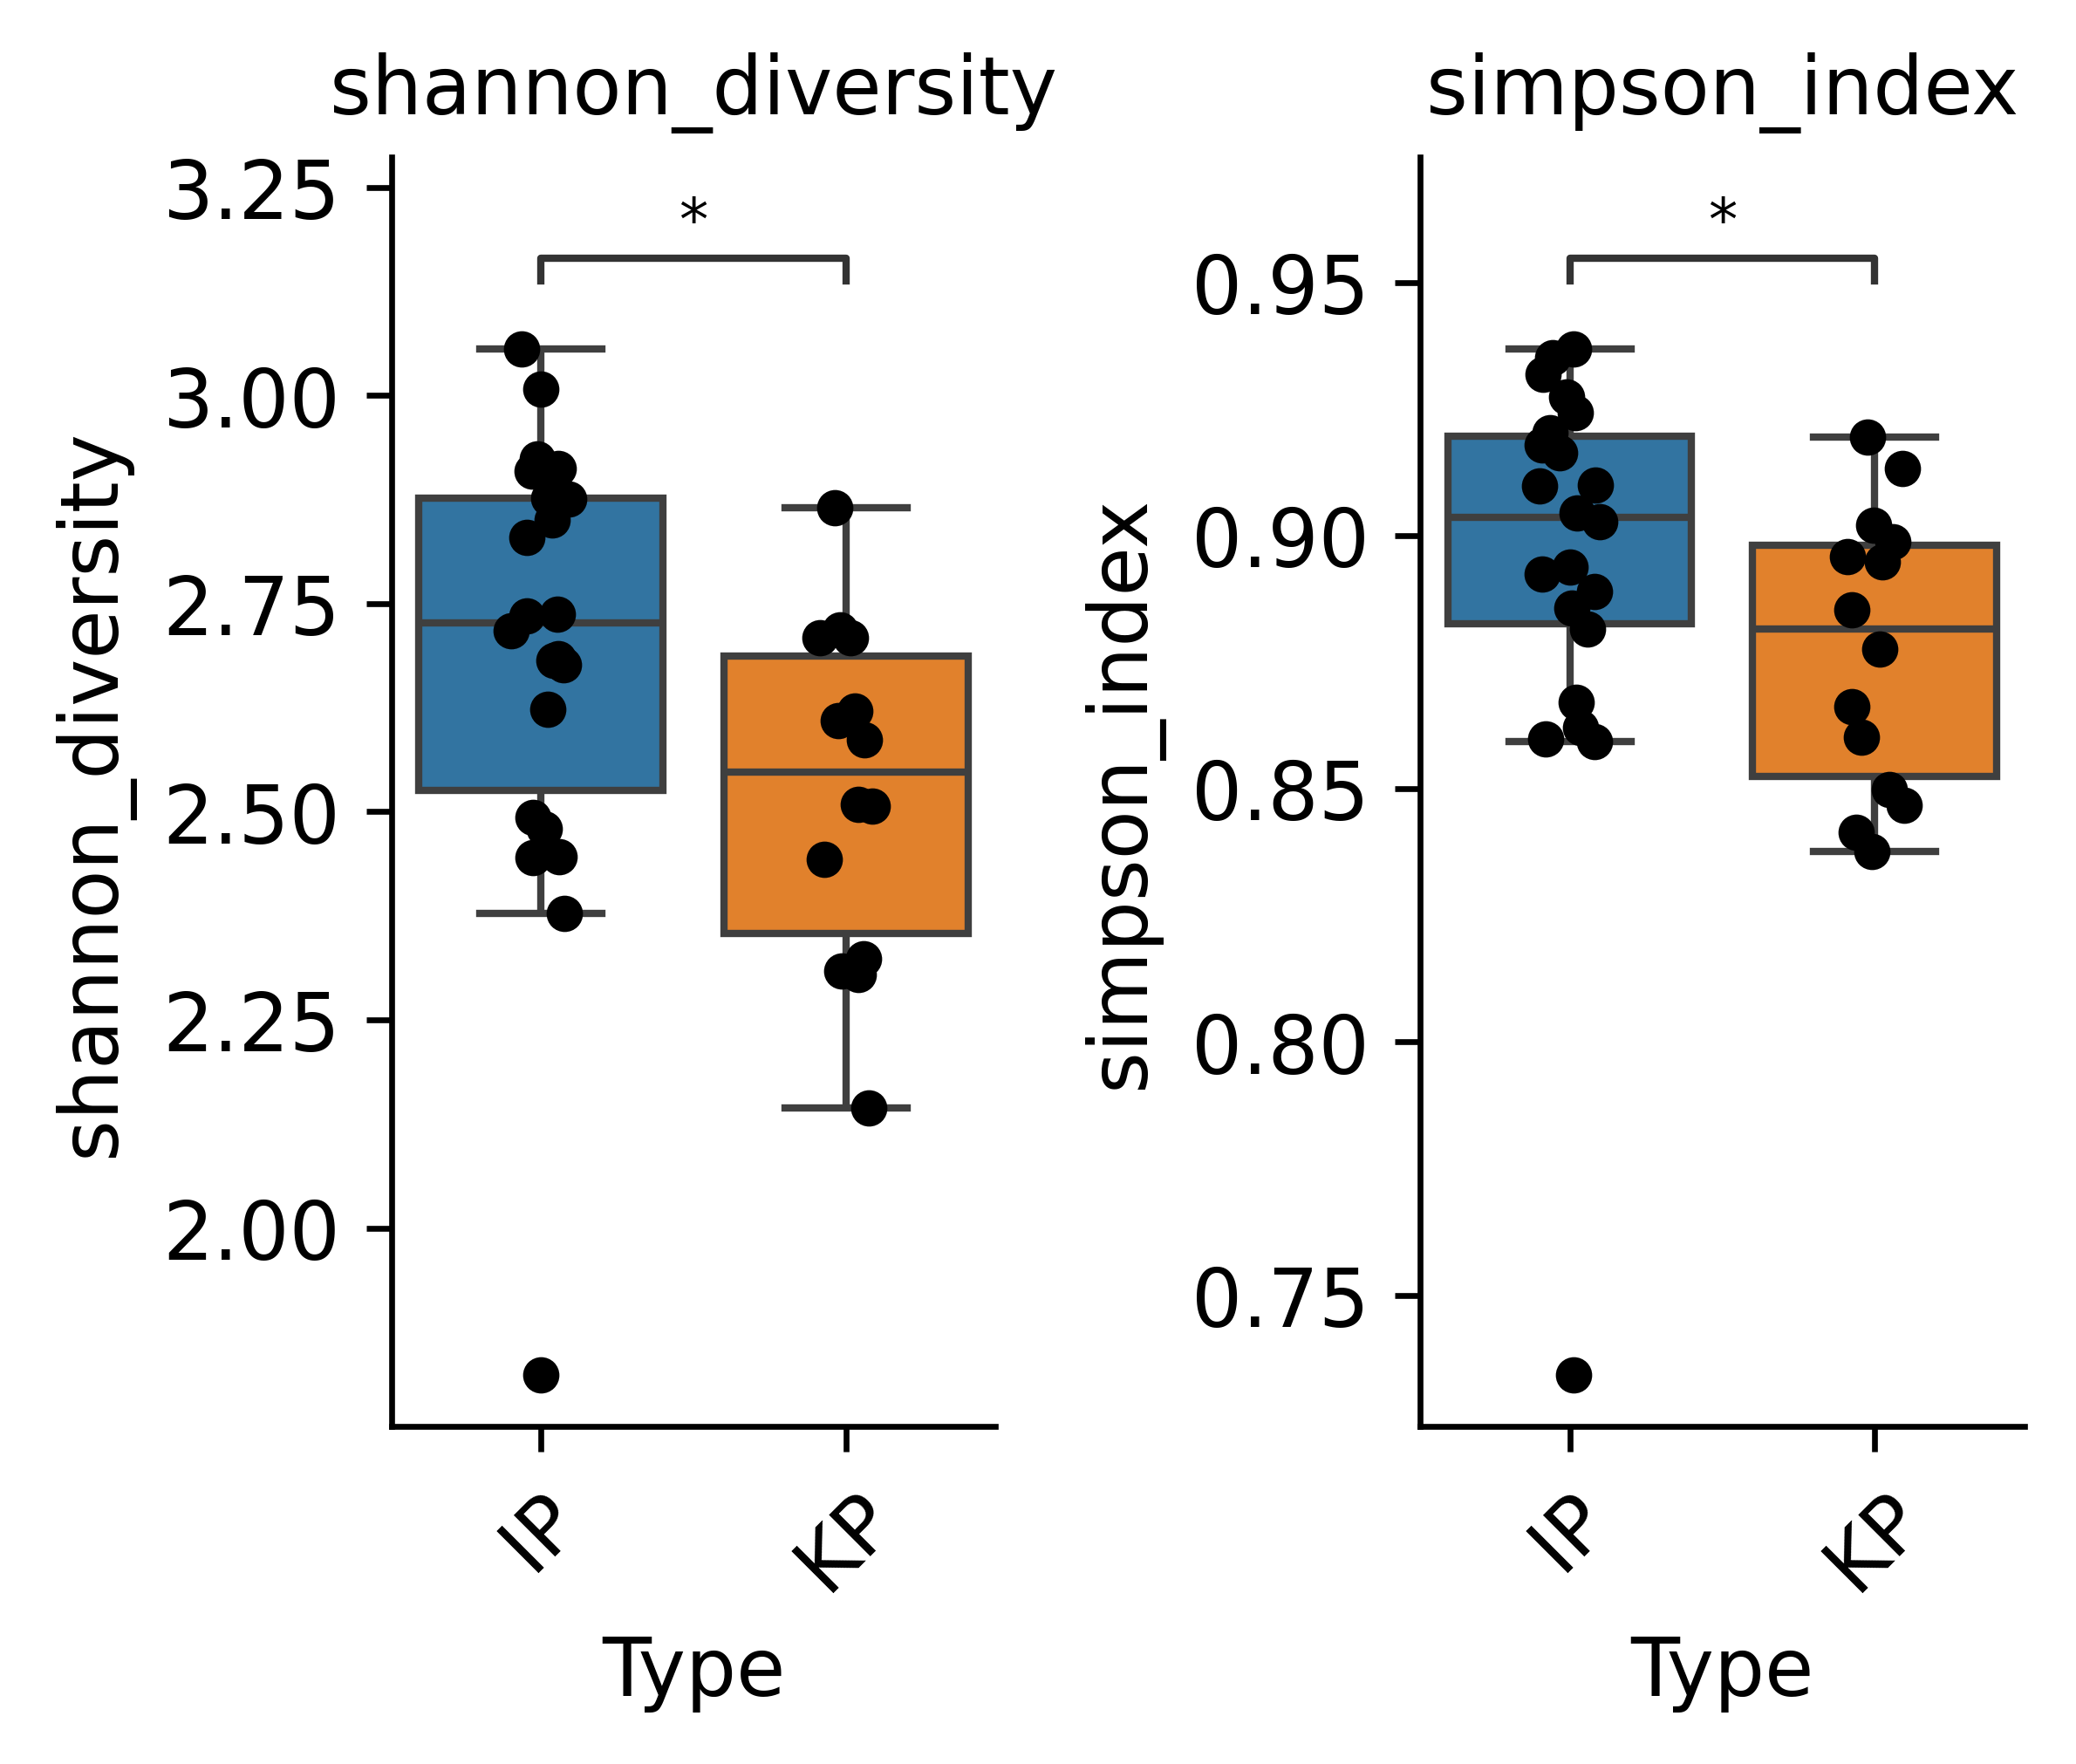

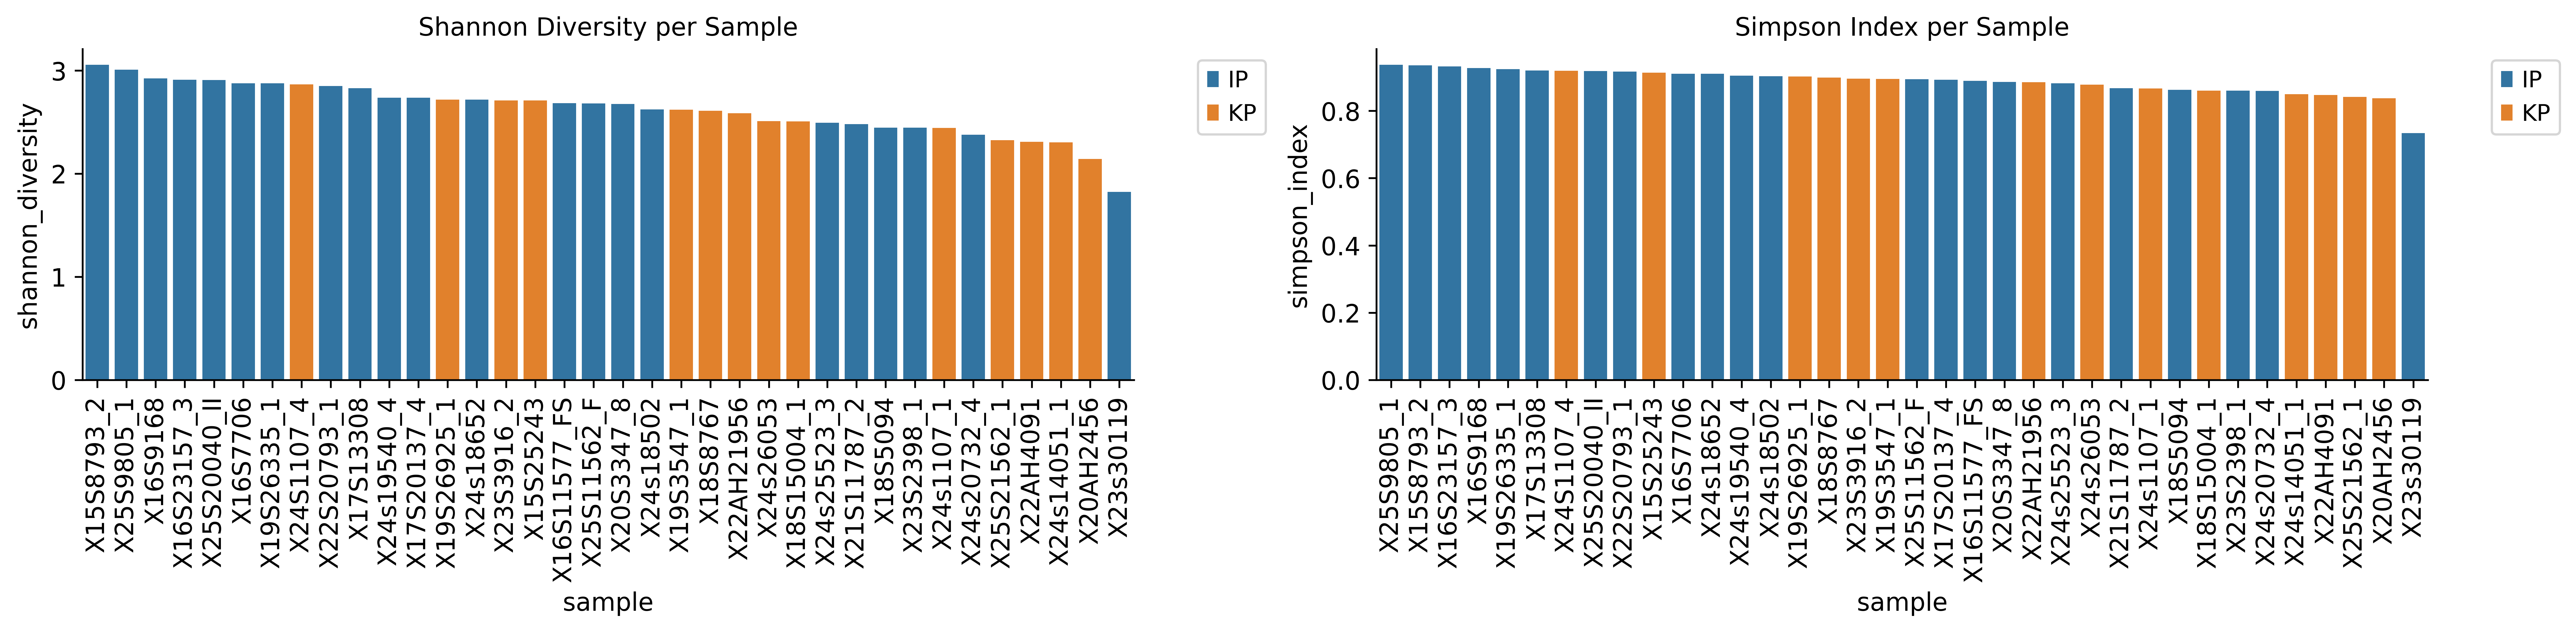

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations
from statannotations.Annotator import Annotator


# 标准Type分组箱线图 + 显著性（推荐！）
fig, axes = plt.subplots(1, 2, figsize=(4, 3.5))
for ax, metric in zip(axes, ["shannon_diversity", "simpson_index"]):
	palette = sns.color_palette("tab10", len(type_list))  # 自动配色
	sns.boxplot(data=div_df, x="Type", y=metric, palette=palette, dodge=False, fliersize=0, ax=ax)  # 
	sns.stripplot(data=div_df, x="Type", y=metric, color="black", s=5, ax=ax)
	# 两两显著性
	type_list = div_df["Type"].unique()
	all_pairs = list(combinations(type_list, 2))
	annotator = Annotator(ax, pairs=all_pairs, data=div_df, x="Type", y=metric)
	annotator.configure(test="Mann-Whitney", comparisons_correction="bonferroni", text_format="star", loc="inside", line_width=1, fontsize=8) #   # 独立 t 检验：t-test_ind, Welch t 检验（推荐）：t-test_welch, 非参数（两组）：Mann-Whitney, 配对：Wilcoxon, 多组：Kruskal
	annotator.apply_and_annotate()
	ax.grid(False)
	ax.tick_params(axis='x', rotation=45)
	ax.set_title(metric)
plt.tight_layout()
save_fig("sample_heterogeneity_boxplot_Type", fig_dir)


plt.figure(figsize=(16,4))
plt.subplot(1,2,1)
# 按 shannon_diversity 降序排序
order_shannon = div_df.sort_values("shannon_diversity", ascending=False)["sample"].values
sns.barplot(data=div_df, x="sample", y="shannon_diversity", hue='Type', order=order_shannon)   # , color="#9b59b6"
plt.grid(False)
plt.xticks(rotation=90)
plt.legend(bbox_to_anchor=(1.05,1), loc="upper left")
plt.title("Shannon Diversity per Sample")
plt.subplot(1,2,2)
# 按 simpson_index 降序排序
order_simpson = div_df.sort_values("simpson_index", ascending=False)["sample"].values
sns.barplot(data=div_df, x="sample", y="simpson_index", hue='Type', order=order_simpson)   # , color="#9b59b6"
plt.grid(False)
plt.xticks(rotation=90)
plt.legend(bbox_to_anchor=(1.05,1), loc="upper left")
plt.title("Simpson Index per Sample")
plt.tight_layout()
save_fig("sample_heterogeneity_barplot_Type", fig_dir)

# --- 新增展示 ---
print(f"✅ Sample heterogeneity quantification completed")
print(f"   ├─ Mean Shannon diversity: {div_df['shannon_diversity'].mean():.3f}")
print(f"   ├─ Mean Simpson index: {div_df['simpson_index'].mean():.3f}")
print(f"   ├─ Most diverse sample: {div_df.loc[div_df['shannon_diversity'].idxmax(), 'sample']}")
print(f"   └─ Least diverse sample: {div_df.loc[div_df['shannon_diversity'].idxmin(), 'sample']}")


In [ ]:

# ==============================================================================
# METHODS: Step 10. Image Index
# ==============================================================================

from statannotations.Annotator import Annotator
from itertools import combinations  # 自动生成所有两两配对

# plt.rcParams['font.size'] = 12
# pd.set_option('display.float_format','%.4e')

features = [
	'Max.PanCK', 'Max.G', 'Max.Membrane', 'Max.CD45', 'Max.Histone', 'Max.rRNA', 'Max.GFAP', 'Max.DAPI'
]

# CellType 小提琴 + 两两Mann-Whitney 
print("=====绘制CellType分组小提琴+显著性=====")
for feat in features:
	try:
		df = adata.obs[[feat,"CellType"]].dropna()
		ct_list = df["CellType"].unique()
		if len(ct_list)<2:
			continue
		# 小提琴
		plt.figure(figsize=(10,4))
		ax = sns.violinplot(x="CellType", y=feat, data=df, inner="box", linewidth=1, palette=adata.uns["CellType_colors"])  # , cut=0, scale="width", inner="box"
		# # 生成全部两两配对
		# xticklabels = [label.get_text() for label in ax.get_xticklabels()]
		# pairs = [(xticklabels[i],xticklabels[i+1]) for i in range(len(xticklabels)-1)]
		# # pairs = [(ct_list[i],ct_list[j]) for i in range(len(ct_list)) for j in range(i+1,len(ct_list))]
		# annotator = Annotator(ax, pairs, data=df, x="CellType", y=feat)
		# # annotator.configure(test="Mann-Whitney", text_format="star", loc="inside", pvalue_thresholds=[[1e-3,"***"],[0.01,"**"],[0.05,"*"],[1,"ns"]])
		# annotator.configure(test="Mann-Whitney", comparisons_correction="bonferroni", text_format="star", loc="inside", line_height=0.01, line_width=1, fontsize=8) #   # 独立 t 检验：t-test_ind, Welch t 检验（推荐）：t-test_welch, 非参数（两组）：Mann-Whitney, 配对：Wilcoxon, 多组：Kruskal
		# annotator.apply_and_annotate()
		plt.grid(False)
		plt.xticks(rotation=45, ha='right', fontsize=10)
		plt.title(f"{feat} | across CellType(all samples)", weight="bold")
		plt.tight_layout()
		save_fig(f"violin_CellType.{feat}", fig_dir)
		plt.close()
	except Exception as e:
		print(f"{feat} skip, err:{e}")
